# 02. Gradient Descent Intuition
### Understanding Optimization on a 1D Convex Function ($f(x) = x^2$)

In machine learning, **optimization** is the process of adjusting parameters to find the minimum of a cost function.

The primary workhorse for this is **Gradient Descent**. Before applying it to datasets with multiple parameters, it is best to build an intuitive mental model using a simple one-dimensional parabola:

$$f(x) = x^2$$

---

### Key Intuition: Moving Downhill
Imagine you are standing on a hill in dense fog. You cannot see the bottom, but you can feel the slope of the ground beneath your feet:
- If the ground slopes **upward to the right** (positive slope), step **left** (decrease $x$).
- If the ground slopes **downward to the right** (negative slope), step **right** (increase $x$).
- The steeper the slope, the larger the step you can take.
- When the slope is zero, you have reached the bottom!

In [2]:
# Step 1: Import visualization and calculation libraries
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: The Function and Its Derivative

For $f(x) = x^2$, calculus gives the derivative (gradient):

$$\frac{df}{dx} = 2x$$

Let's test this at a few points:
- At $x = 4.0$: slope is $+8.0$ (positive $\implies$ move left towards 0).
- At $x = -3.0$: slope is $-6.0$ (negative $\implies$ move right towards 0).
- At $x = 0.0$: slope is $0.0$ (minimum reached!).

In [3]:
# Step 2: Define function f(x) and its derivative grad_f(x)
def f(x):
    """Objective function: f(x) = x^2"""
    return x ** 2

def grad_f(x):
    """Analytical derivative: df/dx = 2x"""
    return 2.0 * x

# Test slope at various points
test_points = [4.0, -3.0, 0.0]
for pt in test_points:
    slope = grad_f(pt)
    direction = "Move Left (decrease x)" if slope > 0 else ("Move Right (increase x)" if slope < 0 else "At Minimum!")
    print(f"At x = {pt:5.1f} | f(x) = {f(pt):5.1f} | df/dx = {slope:5.1f} -> {direction}")

At x =   4.0 | f(x) =  16.0 | df/dx =   8.0 -> Move Left (decrease x)
At x =  -3.0 | f(x) =   9.0 | df/dx =  -6.0 -> Move Right (increase x)
At x =   0.0 | f(x) =   0.0 | df/dx =   0.0 -> At Minimum!


## Section 2: The Gradient Descent Update Rule

At each step (iteration), we update $x$ in the opposite direction of the gradient:

$$x_{t+1} = x_t - \alpha \frac{df}{dx}(x_t)$$

where:
- $x_t$ is the current position at iteration $t$.
- $\alpha$ (alpha) is the **learning rate**: a small positive scalar (e.g., $0.1$) controlling step size.
- $\frac{df}{dx}(x_t)$ is the derivative at the current point.
- The minus sign ($-$) ensures we move **downhill** against the slope.

Let's manually trace the first 5 steps starting from $x_0 = 4.0$ with learning rate $\alpha = 0.15$.

In [4]:
# Step 3: Manual trace of gradient descent
x_cur = 4.0
alpha = 0.15

print("Step-by-step trace of Gradient Descent:")
print(f"{'Iter':<5} | {'x_t':<10} | {'f(x_t)':<10} | {'df/dx':<10} | {'Step (-a*df)':<12} | {'x_{t+1}':<10}")
print("-" * 68)

for t in range(5):
    gradient = grad_f(x_cur)
    step = -alpha * gradient
    x_next = x_cur + step
    print(f"{t:<5d} | {x_cur:<10.4f} | {f(x_cur):<10.4f} | {gradient:<10.4f} | {step:<12.4f} | {x_next:<10.4f}")
    x_cur = x_next

Step-by-step trace of Gradient Descent:
Iter  | x_t        | f(x_t)     | df/dx      | Step (-a*df) | x_{t+1}   
--------------------------------------------------------------------
0     | 4.0000     | 16.0000    | 8.0000     | -1.2000      | 2.8000    
1     | 2.8000     | 7.8400     | 5.6000     | -0.8400      | 1.9600    
2     | 1.9600     | 3.8416     | 3.9200     | -0.5880      | 1.3720    
3     | 1.3720     | 1.8824     | 2.7440     | -0.4116      | 0.9604    
4     | 0.9604     | 0.9224     | 1.9208     | -0.2881      | 0.6723    


## Section 3: The Critical Role of the Learning Rate $\alpha$

The choice of learning rate $\alpha$ is the most critical hyperparameter in gradient descent:
1. **Too Small ($\alpha = 0.02$):** Takes tiny steps; sluggish, wastes computation.
2. **Optimal ($\alpha = 0.20$):** Smooth, rapid convergence directly to the minimum.
3. **Too Large / Oscillating ($\alpha = 0.85$):** Overshoots the minimum, bouncing back and forth across the walls.
4. **Divergent ($\alpha = 1.05$):** Each step overshoots further than the last, exploding to infinity!

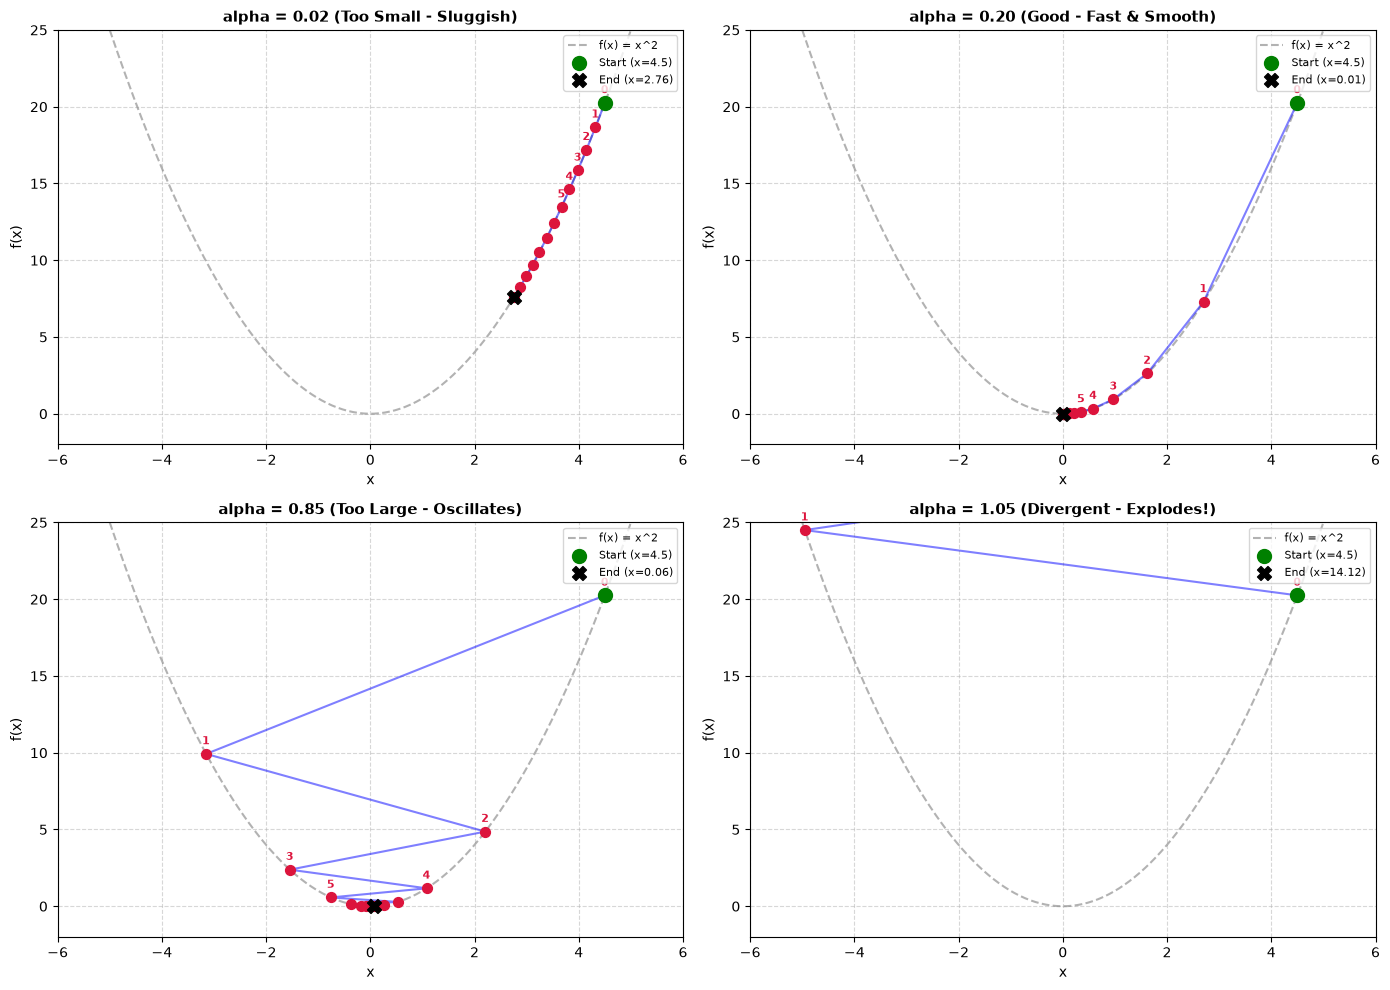

In [5]:
# Step 4: Run gradient descent with different learning rates
def run_gradient_descent(x_start, alpha, num_steps=15):
    """Runs gradient descent on f(x) = x^2 and records trajectory."""
    history_x = [x_start]
    history_f = [f(x_start)]
    x = x_start
    
    for _ in range(num_steps):
        # Update rule: x = x - alpha * df/dx
        x = x - alpha * grad_f(x)
        history_x.append(x)
        history_f.append(f(x))
        # Prevent numerical overflow in diverging case
        if abs(x) > 100:
            break
            
    return np.array(history_x), np.array(history_f)

# Test 4 distinct learning rates
learning_rates = [0.02, 0.20, 0.85, 1.05]
labels = [
    "alpha = 0.02 (Too Small - Sluggish)",
    "alpha = 0.20 (Good - Fast & Smooth)",
    "alpha = 0.85 (Too Large - Oscillates)",
    "alpha = 1.05 (Divergent - Explodes!)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

x_curve = np.linspace(-5, 5, 200)
y_curve = f(x_curve)

for ax, alpha, label in zip(axes, learning_rates, labels):
    hx, hy = run_gradient_descent(x_start=4.5, alpha=alpha, num_steps=12)
    
    # Plot background parabola
    ax.plot(x_curve, y_curve, color='gray', linestyle='--', alpha=0.6, label='f(x) = x^2')
    
    # Plot trajectory path
    ax.plot(hx, hy, color='blue', alpha=0.5, linewidth=1.5)
    ax.scatter(hx, hy, color='crimson', s=50, zorder=4)
    
    # Mark start and end points
    ax.scatter(hx[0], hy[0], color='green', s=100, marker='o', zorder=5, label='Start (x=4.5)')
    ax.scatter(hx[-1], hy[-1], color='black', s=100, marker='X', zorder=5, 
               label=f'End (x={hx[-1]:.2f})')
    
    # Number each step
    for i, (xi, yi) in enumerate(zip(hx[:6], hy[:6])):
        ax.annotate(f"{i}", (xi, yi), textcoords="offset points", xytext=(0, 7), 
                    ha='center', fontsize=8, fontweight='bold', color='crimson')
        
    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.set_xlim(-6, 6)
    ax.set_ylim(-2, 25)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

## Section 4: Tracking Convergence Over Iterations

Let's plot the value of $x$ at each iteration for the non-diverging learning rates.
- Notice how $\alpha = 0.20$ reaches nearly zero in under 10 iterations.
- $\alpha = 0.02$ is still far from zero even after 25 iterations.

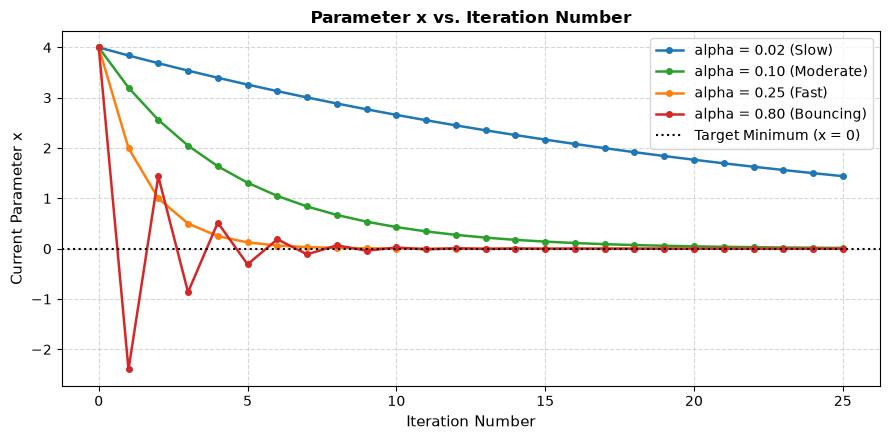

In [6]:
# Step 5: Plotting iteration progress
plt.figure(figsize=(9, 4.5))

for alpha, color, name in zip([0.02, 0.10, 0.25, 0.80], ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728'], 
                              ['alpha = 0.02 (Slow)', 'alpha = 0.10 (Moderate)', 'alpha = 0.25 (Fast)', 'alpha = 0.80 (Bouncing)']):
    hx, _ = run_gradient_descent(x_start=4.0, alpha=alpha, num_steps=25)
    plt.plot(range(len(hx)), hx, marker='o', markersize=4, color=color, linewidth=1.8, label=name)

plt.axhline(0, color='black', linestyle=':', label='Target Minimum (x = 0)')
plt.title('Parameter x vs. Iteration Number', fontsize=12, fontweight='bold')
plt.xlabel('Iteration Number', fontsize=11)
plt.ylabel('Current Parameter x', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Section 5: Stopping Criteria (When to Stop?)

In practice, gradient descent stops when either:
1. **Maximum iterations reached:** A predefined epoch count (e.g., 1000).
2. **Gradient threshold reached:** The gradient magnitude is smaller than a small tolerance $\epsilon$:
$$|\frac{df}{dx}| < 10^{-6}$$
3. **Cost change is negligible:** $|f(x_{t+1}) - f(x_t)| < 10^{-8}$.

In [7]:
# Step 6: Gradient descent with automatic tolerance stopping
x = 4.0
alpha = 0.15
tolerance = 1e-6
max_iters = 100

for epoch in range(1, max_iters + 1):
    grad = grad_f(x)
    x = x - alpha * grad
    if abs(grad) < tolerance:
        print(f"Converged at iteration {epoch}! Final x = {x:.8f}, df/dx = {grad:.8e}")
        break

Converged at iteration 46! Final x = 0.00000030, df/dx = 8.56055235e-07


## Section 6: Key Takeaways

1. **Gradient tells direction:** The derivative points uphill; subtracting the gradient moves downhill.
2. **Automatic step deceleration:** As we get closer to the minimum, the gradient $\frac{df}{dx}$ naturally becomes smaller, so the step size $\alpha \frac{df}{dx}$ automatically shrinks!
3. **Learning rate sensitivity:** Choose $\alpha$ carefully: too small is slow; too big oscillates or diverges.
4. **Next Step:** In Notebook 03, we extend this update rule from single-variable $x^2$ to the two parameters $(w, b)$ of our Qatar rental regression model.